# Machine Learning Lab Week 3: Mini Project 1

In Mini-Project 1,  you will use data from the American Community Survey (ACS) Public Use Microdata Sample (PUMS) to predict the returns to education and inform policy. The project has three parts: 

1. obtaining data from the Internet

2. cleaning that data

3. performing data analysis and answering questions

The goal for today's lab is to get exposure to each of these steps!

## 1. Obtaining data from the Internet

### First, navigate to the IPUMS USA website: https://usa.ipums.org/usa/index.shtml.

Today, the dataset has been obtained for you. But you will get experience searching and downloading data from IPUMS in the Mini Project 1 (part 2). 

In [6]:
# Import required libraries
import numpy as np
import pandas as pd
from sklearn.preprocessing import SplineTransformer
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

from pygam import LinearGAM, s, te

# Display all columns in pandas
pd.set_option('display.max_columns', None)


## 2. Preparing and Cleaning that data

In [2]:
# Load the data
acs_data = pd.read_csv('data/usa_00001.csv')
acs_data.head()

,YEAR,SAMPLE,SERIAL,CBSERIAL,HHWT,CLUSTER,STRATA,GQ,PERNUM,PERWT,NCHILD,SEX,AGE,MARST,RACE,RACED,HISPAN,HISPAND,EDUC,EDUCD,EMPSTAT,EMPSTATD,INCWAGE,VETSTAT,VETSTATD
0,2022,202201,1452,2022010084463,806.0,2022000014521,180101,4,1,806.0,0,1,22,6,1,100,0,0,6,63,1,14,29100,1,12
1,2022,202201,3225,2022000005980,18054.4,2022000032251,40201,1,1,18054.4,2,2,42,1,1,100,0,0,11,114,1,10,135000,1,11
2,2022,202201,3386,2022000016287,18699.2,2022000033861,30001,1,1,18699.2,2,2,50,1,1,100,0,0,8,81,1,10,36000,1,11
3,2022,202201,3386,2022000016287,18699.2,2022000033861,30001,1,2,15314.0,2,1,44,1,8,802,0,0,6,63,1,10,58000,1,11
4,2022,202201,3870,2022000049714,11445.2,2022000038701,200001,1,1,11606.4,2,1,56,1,1,100,0,0,6,63,1,10,46800,1,11


### Using a Crosswalk dataframe - Converting EDUCD to continuous

#### a) Education - EDUCD is a categorical measurement of education. For some of our analysis, we need a continuous variable. Use the original EDUCD variable and the crosswalk to create a continuous measure of education called EDUCDC

**Crosswalk**: refers to a type of data mapping used to align or translate one set of data values to another.

_Question: Can we intuitively explain the difference between a categorical measurement for education vs. a continuous one? (i.e. what is the real-world mean of these two types of data to describe education?)_

- A **categorical measurement** of education sorts educational achievements into distinct groups or categories without implying any numeric value or order

    - *Example*:
        - High school diploma
        - Associate degree
        - Bachelor's degree
        - Master's degree

- A **continuous measurement** of education attempts to quantify education in a way that allows for more nuanced comparisons. This might involve measuring education in terms of years of schooling.

    - *Example*:
        - Each year of schooling equals one unit, so a bachelors degree equates to 16 years of education


In [5]:
# Check unique values of EDUCD in the original data
acs_data['EDUCD'].unique()

NameError: name 'acs_data' is not defined

In [4]:
# read in crosswalk data
crosswalk = pd.read_csv('data/Education-Crosswalk.csv')
crosswalk.head()

,educd,educdc
0,2,0.0
1,10,0.0
2,11,2.0
3,12,0.0
4,13,2.5


In [5]:
# Check unique values of educd in the crosswalk data
crosswalk['educd'].unique()

array([  2,  10,  11,  12,  13,  14,  15,  16,  17,  20,  21,  22,  23,
        24,  25,  26,  30,  40,  50,  61,  62,  63,  64,  65,  70,  71,
        80,  81,  82,  83,  90, 100, 101, 110, 111, 112, 113, 114, 115,
       116])

_Question: What do we notice about the Crosswalk data, and how can we use it to help us with education in the acs data?_

In order to match the 'educd' variable in the crosswalk to the 'EDUCD' variable in the acs data, we need them to have the same name. 

In [6]:
# Capitalize the column names in the crosswalk 
crosswalk = crosswalk.rename(columns={'educd': 'EDUCD', 'educdc': 'EDUCDC'})
crosswalk.head()

,EDUCD,EDUCDC
0,2,0.0
1,10,0.0
2,11,2.0
3,12,0.0
4,13,2.5


In [7]:
# map the matching values of EDUCD between the two dataframes (i.e. merge on EDUCD)
acs_data = acs_data.merge(crosswalk, on='EDUCD')

In [8]:
# check the data for our changes - the new continuous variable will be found at the end 
acs_data.head()

,YEAR,SAMPLE,SERIAL,CBSERIAL,HHWT,CLUSTER,STRATA,GQ,PERNUM,PERWT,NCHILD,SEX,AGE,MARST,RACE,RACED,HISPAN,HISPAND,EDUC,EDUCD,EMPSTAT,EMPSTATD,INCWAGE,VETSTAT,VETSTATD,EDUCDC
0,2022,202201,1452,2022010084463,806.0,2022000014521,180101,4,1,806.0,0,1,22,6,1,100,0,0,6,63,1,14,29100,1,12,12.0
1,2022,202201,3225,2022000005980,18054.4,2022000032251,40201,1,1,18054.4,2,2,42,1,1,100,0,0,11,114,1,10,135000,1,11,18.0
2,2022,202201,3386,2022000016287,18699.2,2022000033861,30001,1,1,18699.2,2,2,50,1,1,100,0,0,8,81,1,10,36000,1,11,14.0
3,2022,202201,3386,2022000016287,18699.2,2022000033861,30001,1,2,15314.0,2,1,44,1,8,802,0,0,6,63,1,10,58000,1,11,12.0
4,2022,202201,3870,2022000049714,11445.2,2022000038701,200001,1,1,11606.4,2,1,56,1,1,100,0,0,6,63,1,10,46800,1,11,12.0


In [4]:
acs_data

NameError: name 'acs_data' is not defined

### Create dummy variables - Convert VETSTAT, RACE, and MARST to dummy

#### b) Veteran Status - Create a dummy variable, VET, equal to 1 if the individual is a veteran.

In [9]:
# Check the unqique values
acs_data['VETSTAT'].unique()
# 2 means a vet, 1 means not -> you can find this in the documentation online & in codebook [Link]

array([1, 2])

In [10]:
## creating a new dummy variable "VET" in the data
## np.where(condition, value assigned when condition met, value assigned when condition not met)
acs_data['VET'] = np.where(acs_data['VETSTAT'] == 2, 1, 0)

VET == 1 if the individual is a vet.

VET == 0 if the individual is not a vet.

#### c) Race - Create dummy variables, WHITE and BLACK, from the RACE variable

In the original data, RACE == 1 when the individual is White, and RACE == 2 when the individual is Black. Create two new dummy variables WHITE and BLACK using this information.

In [11]:
# creating two new dummy variables "WHITE"and "BLACK" in the data
acs_data['WHITE'] = np.where(acs_data['RACE'] == 1, 1, 0)
acs_data['BLACK'] = np.where(acs_data['RACE'] == 2, 1, 0)

WHITE == 1 if the individual is White, 0 otherwise.

BLACK == 1 if the individual is Black, 0 otherwise.

#### d) Marital Status - Create a dummy variable, MAR, equal to 1 if the person is married.

In [12]:
# Check the unqique values
acs_data['MARST'].unique()
# MARST = 1, 2 implies married.  

array([6, 1, 5, 4, 2, 3])

In [13]:
# creating new dummy variable "MAR" in the data
acs_data['MAR'] = np.where(
    (acs_data['MARST'] == 1) | (acs_data['MARST'] == 2),
    1,
    0
)

MAR == 1 if married.


MAR == 0 if not married.

In [14]:
# check the data for our changes - the 4 new dummy variables will be found at the end 
acs_data.head()

,YEAR,SAMPLE,SERIAL,CBSERIAL,HHWT,CLUSTER,STRATA,GQ,PERNUM,PERWT,NCHILD,SEX,AGE,MARST,RACE,RACED,HISPAN,HISPAND,EDUC,EDUCD,EMPSTAT,EMPSTATD,INCWAGE,VETSTAT,VETSTATD,EDUCDC,VET,WHITE,BLACK,MAR
0,2022,202201,1452,2022010084463,806.0,2022000014521,180101,4,1,806.0,0,1,22,6,1,100,0,0,6,63,1,14,29100,1,12,12.0,0,1,0,0
1,2022,202201,3225,2022000005980,18054.4,2022000032251,40201,1,1,18054.4,2,2,42,1,1,100,0,0,11,114,1,10,135000,1,11,18.0,0,1,0,1
2,2022,202201,3386,2022000016287,18699.2,2022000033861,30001,1,1,18699.2,2,2,50,1,1,100,0,0,8,81,1,10,36000,1,11,14.0,0,1,0,1
3,2022,202201,3386,2022000016287,18699.2,2022000033861,30001,1,2,15314.0,2,1,44,1,8,802,0,0,6,63,1,10,58000,1,11,12.0,0,0,0,1
4,2022,202201,3870,2022000049714,11445.2,2022000038701,200001,1,1,11606.4,2,1,56,1,1,100,0,0,6,63,1,10,46800,1,11,12.0,0,1,0,1


Note about conveting categorical to dummy variables:  
There are several possible approaches to encode categorical values, and statsmodels has built-in support
for many of them. In general these work by splitting a categorical variable into many different binary variables. 
The simplest way to encode categoricals is “dummy-encoding” which encodes a k-level categorical variable into k-1 
binary variables. In statsmodels this is done easily using the C() function.

### Geneating new variables - Create new information from the INCWAGE variable 

#### e) Income - Create a new variable for the natural log of INCWAGE

In [15]:
# We first drop those with 0 income. This is because ln(0) is undefined
acs_data = acs_data[acs_data.INCWAGE != 0]
# creating new variable "INCWAGE_log" in the data, the natural log of INCWAGE 
acs_data['INCWAGE_log'] = np.log(acs_data['INCWAGE'])

In [16]:
acs_data[['INCWAGE','INCWAGE_log']].head(10)

,INCWAGE,INCWAGE_log
0,29100,10.278493
1,135000,11.813030
2,36000,10.491274
3,58000,10.968198
4,46800,10.753638
5,9900,9.200290
6,63000,11.050890
7,107000,11.580584
8,65000,11.082143
9,100000,11.512925


#### e) Income - Create a new variable for INCWAGE squared

In [ ]:
# creating new variable "INCWAGESQ" in the data, which is the square of INCWAGE
acs_data['INCWAGESQ'] = np.power(acs_data['INCWAGE'], 2)

In [18]:
# check the data for our changes - the 2 new income variables will be found at the end 
acs_data.head()

,YEAR,SAMPLE,SERIAL,CBSERIAL,HHWT,CLUSTER,STRATA,GQ,PERNUM,PERWT,NCHILD,SEX,AGE,MARST,RACE,RACED,HISPAN,HISPAND,EDUC,EDUCD,EMPSTAT,EMPSTATD,INCWAGE,VETSTAT,VETSTATD,EDUCDC,VET,WHITE,BLACK,MAR,INCWAGE_log,INCWAGESQ
0,2022,202201,1452,2022010084463,806.0,2022000014521,180101,4,1,806.0,0,1,22,6,1,100,0,0,6,63,1,14,29100,1,12,12.0,0,1,0,0,10.278493,846810000
1,2022,202201,3225,2022000005980,18054.4,2022000032251,40201,1,1,18054.4,2,2,42,1,1,100,0,0,11,114,1,10,135000,1,11,18.0,0,1,0,1,11.813030,18225000000
2,2022,202201,3386,2022000016287,18699.2,2022000033861,30001,1,1,18699.2,2,2,50,1,1,100,0,0,8,81,1,10,36000,1,11,14.0,0,1,0,1,10.491274,1296000000
3,2022,202201,3386,2022000016287,18699.2,2022000033861,30001,1,2,15314.0,2,1,44,1,8,802,0,0,6,63,1,10,58000,1,11,12.0,0,0,0,1,10.968198,3364000000
4,2022,202201,3870,2022000049714,11445.2,2022000038701,200001,1,1,11606.4,2,1,56,1,1,100,0,0,6,63,1,10,46800,1,11,12.0,0,1,0,1,10.753638,2190240000


### 3. Performing data analysis and answering questions.

#### Summary statistic (mean, sd) for age variable only

In [19]:
acs_data.columns

Index(['YEAR', 'SAMPLE', 'SERIAL', 'CBSERIAL', 'HHWT', 'CLUSTER', 'STRATA',
       'GQ', 'PERNUM', 'PERWT', 'NCHILD', 'SEX', 'AGE', 'MARST', 'RACE',
       'RACED', 'HISPAN', 'HISPAND', 'EDUC', 'EDUCD', 'EMPSTAT', 'EMPSTATD',
       'INCWAGE', 'VETSTAT', 'VETSTATD', 'EDUCDC', 'VET', 'WHITE', 'BLACK',
       'MAR', 'INCWAGE_log', 'INCWAGESQ'],
      dtype='object')

In [20]:
acs_data['AGE'].describe()

count    8571.000000
mean       41.521176
std        13.452691
min        18.000000
25%        30.000000
50%        41.000000
75%        53.000000
max        65.000000
Name: AGE, dtype: float64

In [21]:
acs_data['AGE'].mean()

np.float64(41.52117605880294)

In [22]:
acs_data['AGE'].std()

np.float64(13.45269123932277)

#### Scatterplot for age vs income

*Remember to use `fig, ax = plt.subplots()` to make your plots, as you learned in Python I and II*

In [23]:
import matplotlib.pyplot as plt

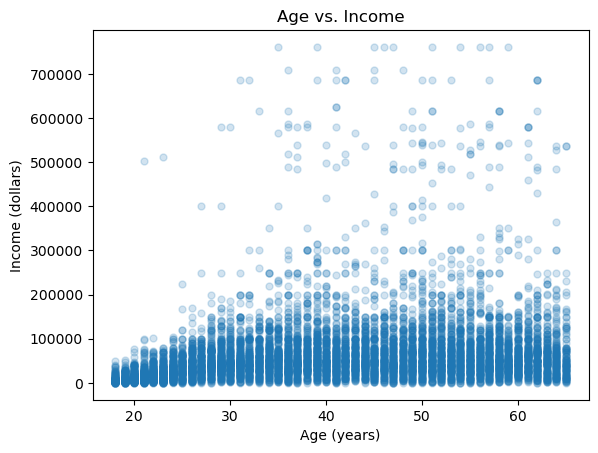

In [24]:
# Create a figure and an axis object
fig, ax = plt.subplots()

# Scatterplot of age vs. income using the ax object
ax.scatter(acs_data['AGE'], acs_data['INCWAGE'], alpha=0.2, s=25)
# Note: alpha controls the transparency (0=transparent, 1=opaque)
#       s controls the size of the scatter plot markers

# Setting the title, and labels using the ax object
ax.set_title('Age vs. Income')
ax.set_xlabel('Age (years)')
ax.set_ylabel('Income (dollars)')

# Display the plot
plt.show()

#### On the graph of age vs. income, include a linear fit line specific to individuals who are married. 

1. Prepare the linear fit line

In [25]:
from sklearn.linear_model import LinearRegression as lm

#subset married individuals only from the acs_data
acs_married_data = acs_data[acs_data['MAR'] == 1]

#fit the linear regression prediction of age vs. income for individuals who are married
y = acs_married_data[['INCWAGE']].values
X = acs_married_data[['AGE' ]].values
y_pred = lm().fit(X, y).predict(X)

2. Plot

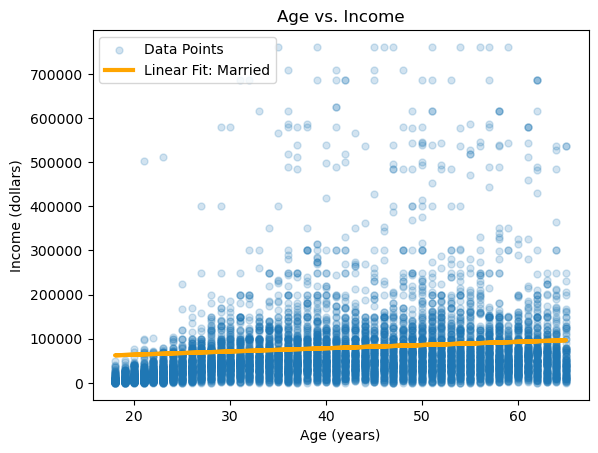

In [26]:
# Create a figure and axis object
fig, ax = plt.subplots()

# Scatterplot of age vs. income
ax.scatter(acs_data['AGE'], acs_data['INCWAGE'], alpha=0.2, s=25, label='Data Points')

# Linear fit line
ax.plot(X, y_pred, color="orange", linewidth=3, label="Linear Fit: Married")

# Setting the title, legend, and labels
ax.set_title('Age vs. Income')
ax.legend()
ax.set_xlabel('Age (years)')
ax.set_ylabel('Income (dollars)')

# Show the plot
plt.show()

### Regressing income only on age and martial status

In [27]:
import statsmodels.formula.api as smf
result = smf.ols('INCWAGE ~ AGE + MAR', data = acs_data).fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                INCWAGE   R-squared:                       0.071
Model:                            OLS   Adj. R-squared:                  0.070
Method:                 Least Squares   F-statistic:                     325.1
Date:                Fri, 16 Oct 2026   Prob (F-statistic):          8.33e-137
Time:                        10:43:07   Log-Likelihood:            -1.0867e+05
No. Observations:                8571   AIC:                         2.173e+05
Df Residuals:                    8568   BIC:                         2.174e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1.437e+04   2722.192      5.280      0.0

#### Discussion Questions:  
(a) What fraction of the variation in wages does the model explain?  
(b) What is the marginal difference in income for being one year older? Is this statistically significant? Is it practically significant? Briefly explain.  
(e) Interpret the coefficient on marital status and its significance.  

#### Discussion Questions (SOLUTIONS):  
(a) What fraction of the variation in wages does the model explain? 

*The fraction of the variation in wages explained by the model is given by the R-squared value, which is 0.071 in this case*

(b) What is the marginal difference in income for being one year older? Is this statistically significant? Is it practically significant? Briefly explain.  

*The marginal difference in income for being one year older is given by the coefficient of the AGE variable, which is 829.2456. This suggests that, all else being equal, each additional year of age is associated with an increase in wages of approximately $829.25.*

*This effect is statistically significant, as indicated by the very small P-value (P<0.0001, far below the conventional threshold of 0.05 for statistical significance).*

(e) Interpret the coefficient on marital status and its significance.  

*The coefficient on marital status (MAR) is 23,070, indicating that, holding age constant, being married is associated with an average increase in wages of $23,070 compared to not being married. This effect is also statistically significant as indicated by the very small P-value (P<0.0001), which means the likelihood of observing such a strong association by chance is very low.*

## Predictions

As an example, what does our model predict the income for a 40-year old, married individual will be? 

In [28]:
# subsetting the data for 40-year-old married individuals only
dat = acs_data.loc[
    (acs_data['MAR'] == 1) & (acs_data['AGE'] == 40)
]

In [29]:
# Expectation for a 40-year-old married individual 
predictions = result.get_prediction(dat)

predictions.summary_frame(alpha=0.05)[:1]
# alpha : significance level for the confidence interval.
# Fix alpha to 0.05 so that the confidence interval should have 95% coverage.

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,77658.897646,1206.184488,75294.485481,80023.30981,-74603.294337,229921.089628


#### **ACTIVITY**: How do you think the model could be improved? Try fitting some different models and report the results of the model that best predicts wages that you can come up with. Use adjusted R2 as your measure of the model that produces the best prediction.

## Splines

We know from lecture that splines are an option for improving fit when we suspect the relationship of our data is non-linear  in total (but can be linear locally!)


In [30]:
X_age = acs_data[["AGE"]]
X_mar = acs_data[["MAR"]]
y = acs_data["INCWAGE"]

#knots must be in the correct array dimension for SplineTransformer (Could also be done by .T on the array and coersing as 2d array)
# Note that the spline transformer needs the boundary knots, not jsut the interior knots. So we pull the age min and age max. 
age_min, age_max = X_age["AGE"].min(), X_age["AGE"].max()
print(X_age["AGE"].min(), X_age["AGE"].max())
print(knots.ravel())

18 65


NameError: name 'knots' is not defined

In [ ]:

# using the above info we have on the age boundaries, we can explicitly code the boundaries into the knots. 
knots = np.array([18, 40, 65]).reshape(-1, 1)

#spline degree is the power of the relationship in the trunkated basis function ,i.e. degree = 1 linear, = 2 quadratic, = 3 cubic 
spline_transformer = SplineTransformer(degree=1, knots=knots, include_bias=False)

# Transform AGE into spline basis functions
X_splines = spline_transformer.fit_transform(X_age)

# Combine spline features and marriage
X = np.hstack([X_splines, X_mar])

model = LinearRegression()
model.fit(X, y)

# Print intercept and coefficients
print("Intercept:", model.intercept_)

# Combine coefficient names for output
spline_columns = [f"spline_{i}" for i in range(X_splines.shape[1])]
all_columns = spline_columns + ["MAR"]
coefficients = pd.Series(model.coef_, index=all_columns)
print("Coefficients:")
print(coefficients)

# Calculate R^2
r_squared = model.score(X, y)

n = len(y)  
p = X.shape[1]  # dfs used (spline features); since adjusted R-squared penalizes the total number of predictors in the fitted model, p should count all columns in X:
adjusted_r_squared = 1 - ((1 - r_squared) * (n - 1)) / (n - p - 1)
print("Adjusted R-squared:", adjusted_r_squared)


Intercept: 61016.918907588304
Coefficients:
spline_0   -46876.582566
spline_1     7223.682966
MAR         22765.765009
dtype: float64
Adjusted R-squared: 0.08240664252400509


# Visualization of our spline

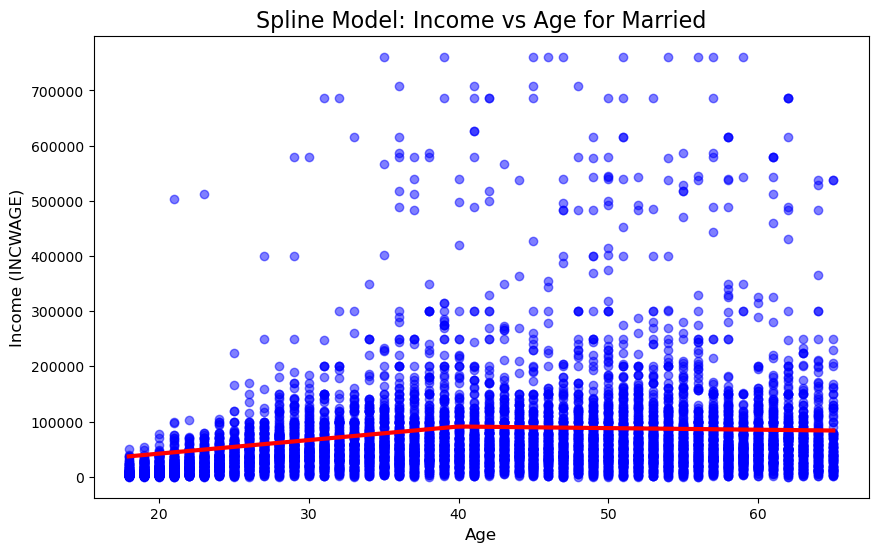

In [ ]:
age_grid = pd.DataFrame({
    "AGE": np.linspace(acs_data["AGE"].min(), acs_data["AGE"].max(), 100),
    "MAR": 1  #for this visualization we're plotting all ages conditional on being married, so we generate a sequence of all ages.
})

age_grid_splines = spline_transformer.transform(age_grid[["AGE"]])
X_grid = np.hstack([age_grid_splines, age_grid[["MAR"]]])
age_grid["predicted"] = model.predict(X_grid) # predict takes a vector predictors similar to regular regression, AGE, MAR ect.



plt.figure(figsize=(10, 6))
plt.scatter(acs_data["AGE"], acs_data["INCWAGE"], alpha=0.5, color="blue", label="Data")
plt.plot(age_grid["AGE"], age_grid["predicted"], color="red", linewidth=3, label="Spline Fit (MAR=1)")
plt.title("Spline Model: Income vs Age for Married", fontsize=16)
plt.xlabel("Age", fontsize=12)
plt.ylabel("Income (INCWAGE)", fontsize=12)
plt.show()


## Generalized Additive Models (GAMs)

Generalized Additive Models are an extension of linear regression which allow for non-linear relationships by allowing each predictor to have it's own curve (often similar to splines) while retaining the interperatability we know and love from linear regression.

LinearGAM                                                                                                 
=============================================== ==========================================================
Distribution:                        NormalDist Effective DoF:                                     40.3547
Link Function:                     IdentityLink Log Likelihood:                               -108008.5176
Number of Samples:                         8571 AIC:                                           216099.7445
                                                AICc:                                          216100.1553
                                                GCV:                                       5234756928.8668
                                                Scale:                                          72044.5103
                                                Pseudo R-Squared:                                   0.2037
Feature Function                  Lam

/var/folders/h9/jpqct8f93r1gkvd9mw5dk6f40000gn/T/ipykernel_9070/2927596566.py:12: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  print(gam_model.summary())


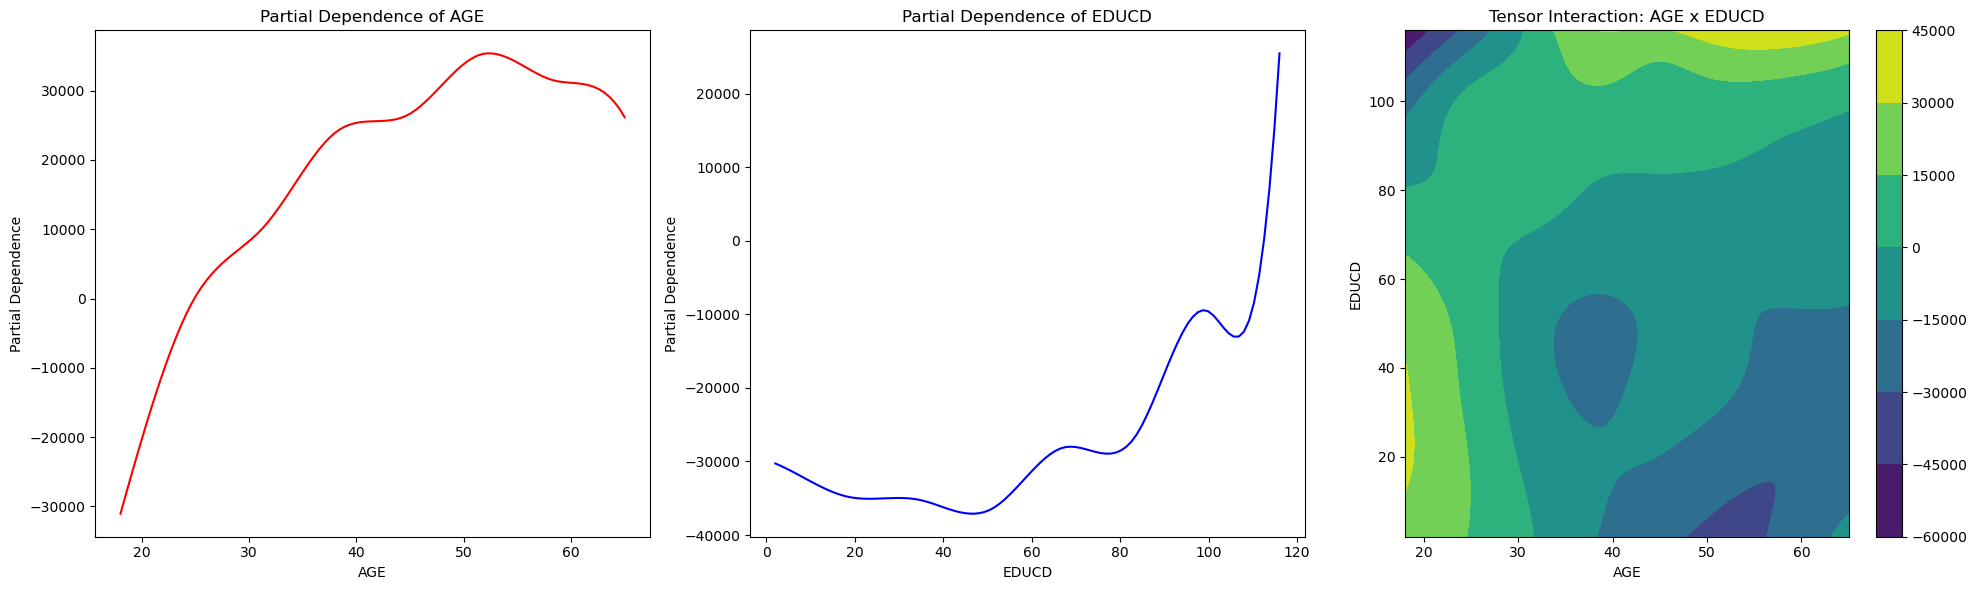

In [ ]:
X = acs_data[["AGE", "EDUCD", "MAR"]].values  # Include AGE, EDUCD, and MAR
y = acs_data["INCWAGE"].values

# Fit GAM model
gam_model = LinearGAM(
    s(0, n_splines=10, spline_order=3) + # Cubic spline for AGE
    s(1, n_splines=10, spline_order=3) +  # Cubic spline for  EDUCD
    te(0, 1, n_splines=[10, 10], spline_order=3) +  #interaction between AGE and EDUCD (look up tensor interaction if interested)
    s(2, spline_order=0)  # MAR as piecewise constant i.e. degree 0
    ).fit(X, y)

print(gam_model.summary())

#plotting these are slightly complicated in python 
age_grid = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)
educd_grid = np.linspace(X[:, 1].min(), X[:, 1].max(), 100)
constant_mar = 1  

fig, axs = plt.subplots(1, 3, figsize=(20, 6))

# smooth term for AGE
X_partial_age = np.zeros((len(age_grid), X.shape[1]))
X_partial_age[:, 0] = age_grid
X_partial_age[:, 2] = constant_mar
partial_dep_age = gam_model.partial_dependence(term=0, X=X_partial_age)
axs[0].plot(age_grid, partial_dep_age, color="red", label="AGE")
axs[0].set_title("Partial Dependence of AGE")
axs[0].set_xlabel("AGE")
axs[0].set_ylabel("Partial Dependence")

# smooth term for EDUCD
X_partial_educd = np.zeros((len(educd_grid), X.shape[1]))
X_partial_educd[:, 1] = educd_grid
X_partial_educd[:, 2] = constant_mar
partial_dep_educd = gam_model.partial_dependence(term=1, X=X_partial_educd)
axs[1].plot(educd_grid, partial_dep_educd, color="blue", label="EDUCD")
axs[1].set_title("Partial Dependence of EDUCD")
axs[1].set_xlabel("EDUCD")
axs[1].set_ylabel("Partial Dependence")

# tensor interaction (AGE x EDUCD)
X_tensor = np.array([[a, e, constant_mar] for a in age_grid for e in educd_grid])
partial_dep_tensor = gam_model.partial_dependence(term=2, X=X_tensor).reshape(len(age_grid), len(educd_grid)).T # each row of the matrix represents Y, and column represents X
contour = axs[2].contourf(age_grid, educd_grid, partial_dep_tensor, cmap="viridis")
fig.colorbar(contour, ax=axs[2])
axs[2].set_title("Tensor Interaction: AGE x EDUCD")
axs[2].set_xlabel("AGE")
axs[2].set_ylabel("EDUCD")

fig.tight_layout()
plt.show()